In [ ]:
import torch
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
from torch import nn
from sklearn.preprocessing import StandardScaler
from torch.optim import Adam
import numpy as np
from torchmetrics.classification import MulticlassAccuracy, PrecisionRecallCurve, ConfusionMatrix

torch.manual_seed(26)

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [ ]:
transform = transforms.ToTensor()

In [ ]:
train_dataset = datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)
test_dataset = datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.74MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 21.4MB/s]


In [ ]:
train_data, validation_data = random_split(train_dataset, [50000, 10000])
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
validation_loader = DataLoader(validation_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=True)

In [ ]:
tensor = torch.tensor(np.arange(16).reshape(4, 4), dtype=torch.float)
tensor[:2]

tensor([[0., 1., 2., 3.],
        [4., 5., 6., 7.]])

In [ ]:
batch_norm = nn.BatchNorm1d(num_features=4)
batch_norm(tensor[:2])

tensor([[-1.0000, -1.0000, -1.0000, -1.0000],
        [ 1.0000,  1.0000,  1.0000,  1.0000]],
       grad_fn=<NativeBatchNormBackward0>)

In [ ]:
scaler = StandardScaler()
scaler.fit_transform(tensor[:2])

array([[-1., -1., -1., -1.],
       [ 1.,  1.,  1.,  1.]])

In [ ]:
batch_norm.weight

Parameter containing:
tensor([1., 1., 1., 1.], requires_grad=True)

In [ ]:
batch_norm.running_mean

tensor([0.2000, 0.3000, 0.4000, 0.5000])

In [ ]:
batch_norm.running_var

tensor([1.7000, 1.7000, 1.7000, 1.7000])

In [ ]:
batch_norm.bias

Parameter containing:
tensor([0., 0., 0., 0.], requires_grad=True)

In [ ]:
tensor[:2]

tensor([[0., 1., 2., 3.],
        [4., 5., 6., 7.]])

In [ ]:
torch.mean(tensor[:2], dim=0)

tensor([2., 3., 4., 5.])

So this is batch normalization, we send the data in batches(not full or small numbers like 1 or 2) so at each layer before the activation it uses z scaling
then the gamma (element multiplcaition for every features) with standarized X then adds the beta which shifts these acts learnable paramters, they decide whether the normalization is required or not, they can cancel out the normalization as well, so the second thing is that for testing it does not normalize by batches it normalizes by the runnign mean and var after the traingin and scales and shifts the beta and gamma learned during the traininin


If you include a bias in the linear layer *and* use Batch Normalization, **the linear layer's bias does literally nothing.** It becomes a "dead" parameter that never learns, and its values are completely ignored.

Here is why mathematically:

### The Math: Why the Linear Bias Dies

1. Your linear layer calculates:

$$z = Wx + b_{\text{linear}}$$


2. Batch Normalization's very first step is to calculate the mean of the batch and subtract it:

$$\text{Mean}(z) = \text{Mean}(Wx + b_{\text{linear}}) = \text{Mean}(Wx) + b_{\text{linear}}$$


3. When BatchNorm subtracts the mean from $z$:

$$z - \text{Mean}(z) = (Wx + b_{\text{linear}}) - (\text{Mean}(Wx) + b_{\text{linear}})$$


$$= Wx - \text{Mean}(Wx)$$



The linear layer's bias ($b_{\text{linear}}$) is **subtracted from itself and vanishes entirely**. It is mathematically impossible for it to affect the output because the mean-centering step erases any constant added before it.

### What about gradients? (Why it doesn't learn)

Because $b_{\text{linear}}$ has zero effect on the final output, it has **zero gradient** during backpropagation ($\frac{\partial \text{Loss}}{\partial b_{\text{linear}}} = 0$). The optimizer will never update it. It just sits in memory taking up space doing nothing.

### Summary

* **Linear Bias ($b_{\text{linear}}$):** Erased by mean subtraction. Useless.
* **BatchNorm Bias ($\beta$):** Added *after* normalization, so it survives, learns, and acts as the true bias for the layer.

This is why deep learning frameworks and engineers always set `bias=False` on linear or convolutional layers right before a BatchNorm layer—to clean up dead parameters and save a tiny bit of memory!

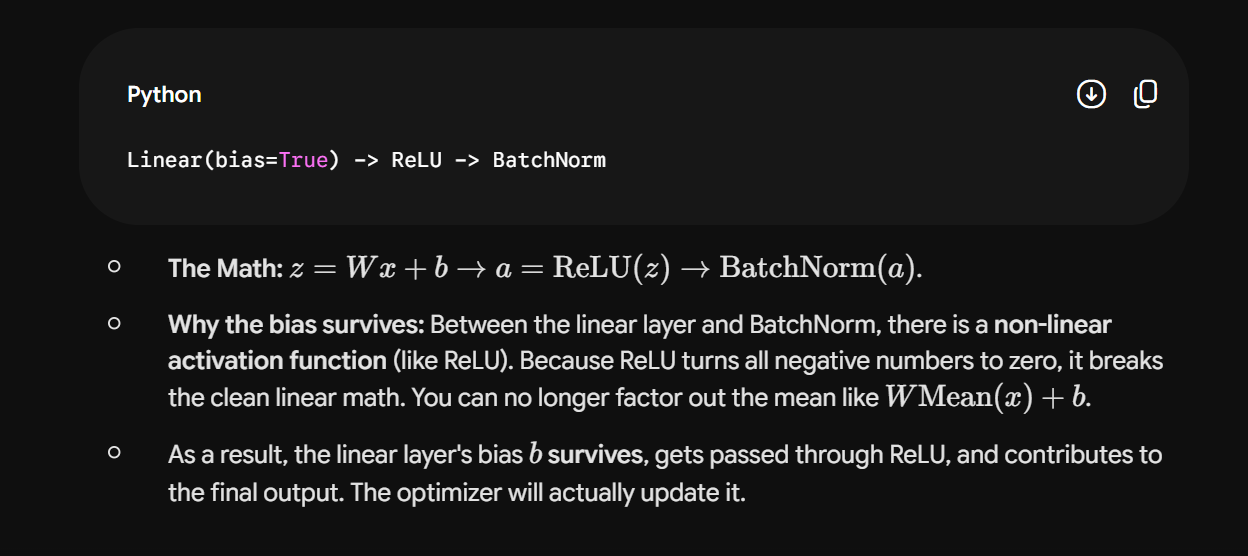

The reason we add the batch norm, because kaimin address for the fan_in, and then it is for step 0 the setup, then the weights gets updates by itself, that is just weight initalization , and the variance might mismatch again druing the training

Once the optimizer starts updating the weights via backpropagation, everything changes.

As Layer 1's weights update, its output distribution shifts. Because Layer 1 feeds into Layer 2, Layer 2's input distribution now changes too. This continuous shifting of feature distributions across layers as weights update is what deep learning researchers call Internal Covariate Shift.

Even if you started with perfect Kaiming initialization, after 100 steps of gradient descent, the weights have changed so much that the variance can drift wildly again, leading back to exploding/vanishing gradients or slow training.

In [ ]:
class Swiglu(nn.Module):
  def __init__(self):
    super().__init__()
  def forward(self, X):
    X1, X2 = torch.chunk(input=X, chunks=2, dim=-1)
    return X1*torch.sigmoid(X2)

def kaiming_init(m):
  if isinstance(m, nn.Linear):
    nn.init.kaiming_normal_(m.weight, mode='fan_in', a=0.25, nonlinearity='leaky_relu')

class Classifier(nn.Module):
  def __init__(self, n_hidden_1, n_hidden_2):
    super().__init__()
    self.model = nn.Sequential(
        nn.Flatten(),
        nn.Linear(28*28, n_hidden_1, bias=False),
        nn.BatchNorm1d(n_hidden_1, momentum=0.01),
        nn.PReLU(),
        nn.Linear(n_hidden_1, n_hidden_2, bias=False),
        nn.BatchNorm1d(n_hidden_2, momentum=0.01),
        nn.PReLU(),
        nn.Linear(n_hidden_2, 10, bias=True)
    )
  def forward(self, X:torch.tensor):
    return self.model(X)

  def train_and_validate(self, train_loader, valid_loader, optimizer, loss_function, epochs):
    train_history, valid_history = [], []
    for epoch in range(epochs):
      self.train()
      train_loss, valid_loss = 0, 0
      for X_train, y_train in train_loader:
        X_train = X_train.to(device)
        y_train = y_train.to(device)
        loss = loss_function(self(X_train), y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()


      self.eval()
      with torch.inference_mode():
        for X_valid, y_valid in valid_loader:
          X_valid = X_valid.to(device)
          y_valid = y_valid.to(device)
          loss = loss_function(self(X_valid), y_valid)
          valid_loss += loss.item()
      valid_history.append(valid_loss/len(valid_loader))
      train_history.append(train_loss/len(train_loader))
      if valid_history[-1] < 0.1:
        break

    plt.figure(figsize=(6,4))
    plt.plot(train_history, label='train')
    plt.plot(valid_history, label='valid')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()


In [ ]:
model = Classifier(64, 32).to(device)
model.apply(kaiming_init)

Classifier(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=64, bias=False)
    (2): BatchNorm1d(64, eps=1e-05, momentum=0.01, affine=True, bias=True, track_running_stats=True)
    (3): PReLU(num_parameters=1)
    (4): Linear(in_features=64, out_features=32, bias=False)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.01, affine=True, bias=True, track_running_stats=True)
    (6): PReLU(num_parameters=1)
    (7): Linear(in_features=32, out_features=10, bias=True)
  )
)

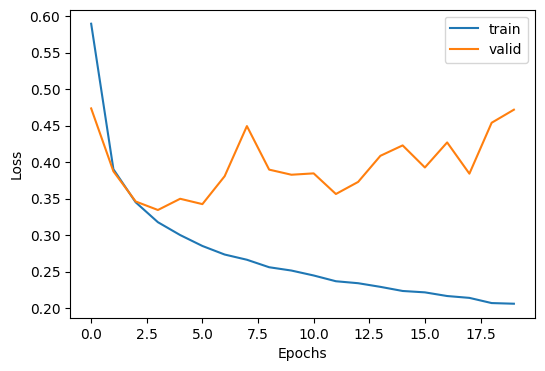

In [ ]:
optimizer = torch.optim.Adam(weight_decay=1e-3, params=model.parameters(), lr=1e-3)
loss_function = nn.CrossEntropyLoss()
epochs=20
model.train_and_validate(train_loader, validation_loader, optimizer, loss_function, epochs)

In [ ]:
metric = MulticlassAccuracy(10).to(device)
with torch.inference_mode():
  for X_test, y_test in test_loader:
    X_test = X_test.to(device)
    y_test = y_test.to(device)
    y_pred = model(X_test)
    metric.update(y_pred, y_test)
metric.compute()

tensor(0.8332, device='cuda:0')

In [ ]:
loss_function

CrossEntropyLoss()

In [ ]:
loss_function(y_pred, y_test)

tensor(0.2381, device='cuda:0')

In [ ]:
# Understanding 1d 2d 3d


In [ ]:
X = torch.randn(3, 4).to(device)
linear_layer = nn.Linear(4, 6, bias=False).to(device)
linear_layer(X)

tensor([[-0.4747,  0.6636, -0.4044,  0.3941, -0.1661,  0.6058],
        [ 0.0450,  0.1553, -0.4889, -0.2438, -0.1178,  0.1130],
        [-0.6466,  0.6075, -0.5780,  0.6902, -1.1586,  1.1743]],
       device='cuda:0', grad_fn=<MmBackward0>)

In [ ]:
torch.matmul(X[0, :], linear_layer.weight.T)

tensor([-0.4747,  0.6636, -0.4044,  0.3941, -0.1661,  0.6058], device='cuda:0',
       grad_fn=<SqueezeBackward4>)

In [ ]:
linear_layer.weight.T.shape

torch.Size([4, 6])

In [ ]:
X = torch.tensor(np.random.normal(69, 0.3, size=(2, 6, 2)),
                 dtype=torch.float).to(device)
X

tensor([[[69.1796, 69.1508],
         [68.6912, 68.7082],
         [68.6410, 68.9945],
         [69.0894, 68.7865],
         [69.3138, 68.9748],
         [69.0507, 68.9508]],

        [[68.8267, 69.4256],
         [69.1411, 68.4875],
         [69.3280, 69.6710],
         [69.1584, 69.0724],
         [68.9585, 68.7975],
         [69.1096, 68.5587]]], device='cuda:0')

In [ ]:
torch.mean(X, dim=0), torch.mean(X, dim=0).shape

(tensor([[69.0031, 69.2882],
         [68.9162, 68.5979],
         [68.9845, 69.3328],
         [69.1239, 68.9294],
         [69.1362, 68.8862],
         [69.0802, 68.7548]], device='cuda:0'),
 torch.Size([6, 2]))

In [ ]:
norm = nn.BatchNorm1d(2).to(device)
try :
  norm(X)
except Exception as e:
  print(e)

running_mean should contain 6 elements not 2


This is failing because torch works on (batches, channels/features, rows)

In [ ]:
tensor = torch.permute(X, (0, 2, 1))
tensor

tensor([[[69.1796, 68.6912, 68.6410, 69.0894, 69.3138, 69.0507],
         [69.1508, 68.7082, 68.9945, 68.7865, 68.9748, 68.9508]],

        [[68.8267, 69.1411, 69.3280, 69.1584, 68.9585, 69.1096],
         [69.4256, 68.4875, 69.6710, 69.0724, 68.7975, 68.5587]]],
       device='cuda:0')

In [ ]:
norm = nn.BatchNorm1d(2).to(device)
try :
  norm(tensor)
except Exception as e:
  print(e)
norm(tensor)

tensor([[[ 0.6535, -1.6440, -1.8804,  0.2294,  1.2851,  0.0473],
         [ 0.5700, -0.7867,  0.0909, -0.5469,  0.0306, -0.0432]],

        [[-1.0067,  0.4724,  1.3517,  0.5540, -0.3866,  0.3243],
         [ 1.4123, -1.4635,  2.1648,  0.3296, -0.5132, -1.2450]]],
       device='cuda:0', grad_fn=<CudnnBatchNormBackward0>)

In [ ]:
torch.permute(norm(tensor), (0, 2, 1))

tensor([[[ 0.6535,  0.5700],
         [-1.6440, -0.7867],
         [-1.8804,  0.0909],
         [ 0.2294, -0.5469],
         [ 1.2851,  0.0306],
         [ 0.0473, -0.0432]],

        [[-1.0067,  1.4123],
         [ 0.4724, -1.4635],
         [ 1.3517,  2.1648],
         [ 0.5540,  0.3296],
         [-0.3866, -0.5132],
         [ 0.3243, -1.2450]]], device='cuda:0', grad_fn=<PermuteBackward0>)

In [ ]:
norm(tensor)

tensor([[[ 0.6535, -1.6440, -1.8804,  0.2294,  1.2851,  0.0473],
         [ 0.5700, -0.7867,  0.0909, -0.5469,  0.0306, -0.0432]],

        [[-1.0067,  0.4724,  1.3517,  0.5540, -0.3866,  0.3243],
         [ 1.4123, -1.4635,  2.1648,  0.3296, -0.5132, -1.2450]]],
       device='cuda:0', grad_fn=<CudnnBatchNormBackward0>)

In [ ]:
norm(tensor)[:, 0, :].flatten().mean()

tensor(1.1226e-06, device='cuda:0', grad_fn=<MeanBackward0>)

In [ ]:
torch.mean(norm(tensor), dim=(0, 2))

tensor([ 1.1226e-06, -1.2954e-05], device='cuda:0', grad_fn=<MeanBackward1>)

In [ ]:
arr = torch.randn(2, 28, 28)
flatten_layer = nn.Flatten()
arrr = flatten_layer(arr)
arrr.shape

torch.Size([2, 784])

In [ ]:
arr = torch.randn(3, 2, 5)
arr

tensor([[[-1.0123, -0.9459,  1.1958, -0.7034, -0.0515],
         [ 0.6552,  0.1683,  0.2564,  0.0410,  1.4114]],

        [[-0.7599, -0.2588, -0.0688, -1.5857,  0.4179],
         [-0.3720, -0.6262,  0.4971, -1.1402,  3.5309]],

        [[ 0.0661,  0.6693,  1.4649, -2.0815,  1.1353],
         [ 0.4664,  2.2017, -0.4104, -0.4872,  0.5269]]])

In [ ]:
torch.cat((arr, arr), dim=0), torch.cat((arr, arr), dim=0).shape

(tensor([[[-1.0123, -0.9459,  1.1958, -0.7034, -0.0515],
          [ 0.6552,  0.1683,  0.2564,  0.0410,  1.4114]],
 
         [[-0.7599, -0.2588, -0.0688, -1.5857,  0.4179],
          [-0.3720, -0.6262,  0.4971, -1.1402,  3.5309]],
 
         [[ 0.0661,  0.6693,  1.4649, -2.0815,  1.1353],
          [ 0.4664,  2.2017, -0.4104, -0.4872,  0.5269]],
 
         [[-1.0123, -0.9459,  1.1958, -0.7034, -0.0515],
          [ 0.6552,  0.1683,  0.2564,  0.0410,  1.4114]],
 
         [[-0.7599, -0.2588, -0.0688, -1.5857,  0.4179],
          [-0.3720, -0.6262,  0.4971, -1.1402,  3.5309]],
 
         [[ 0.0661,  0.6693,  1.4649, -2.0815,  1.1353],
          [ 0.4664,  2.2017, -0.4104, -0.4872,  0.5269]]]),
 torch.Size([6, 2, 5]))

In [ ]:
torch.cat((arr, arr), dim=1), torch.cat((arr, arr), dim=1).shape

(tensor([[[-1.0123, -0.9459,  1.1958, -0.7034, -0.0515],
          [ 0.6552,  0.1683,  0.2564,  0.0410,  1.4114],
          [-1.0123, -0.9459,  1.1958, -0.7034, -0.0515],
          [ 0.6552,  0.1683,  0.2564,  0.0410,  1.4114]],
 
         [[-0.7599, -0.2588, -0.0688, -1.5857,  0.4179],
          [-0.3720, -0.6262,  0.4971, -1.1402,  3.5309],
          [-0.7599, -0.2588, -0.0688, -1.5857,  0.4179],
          [-0.3720, -0.6262,  0.4971, -1.1402,  3.5309]],
 
         [[ 0.0661,  0.6693,  1.4649, -2.0815,  1.1353],
          [ 0.4664,  2.2017, -0.4104, -0.4872,  0.5269],
          [ 0.0661,  0.6693,  1.4649, -2.0815,  1.1353],
          [ 0.4664,  2.2017, -0.4104, -0.4872,  0.5269]]]),
 torch.Size([3, 4, 5]))

In [ ]:
torch.cat((arr, arr), dim=2), torch.cat((arr, arr), dim=2).shape

(tensor([[[-1.0123, -0.9459,  1.1958, -0.7034, -0.0515, -1.0123, -0.9459,
            1.1958, -0.7034, -0.0515],
          [ 0.6552,  0.1683,  0.2564,  0.0410,  1.4114,  0.6552,  0.1683,
            0.2564,  0.0410,  1.4114]],
 
         [[-0.7599, -0.2588, -0.0688, -1.5857,  0.4179, -0.7599, -0.2588,
           -0.0688, -1.5857,  0.4179],
          [-0.3720, -0.6262,  0.4971, -1.1402,  3.5309, -0.3720, -0.6262,
            0.4971, -1.1402,  3.5309]],
 
         [[ 0.0661,  0.6693,  1.4649, -2.0815,  1.1353,  0.0661,  0.6693,
            1.4649, -2.0815,  1.1353],
          [ 0.4664,  2.2017, -0.4104, -0.4872,  0.5269,  0.4664,  2.2017,
           -0.4104, -0.4872,  0.5269]]]),
 torch.Size([3, 2, 10]))

In [ ]:
train_loader = DataLoader(train_dataset, shuffle=True, batch_size=3)
for i, *X in enumerate(train_loader):
  if i == 0:
    X = X[0]
    break


In [ ]:
X, *y = X

In [ ]:
X.shape

torch.Size([3, 1, 28, 28])

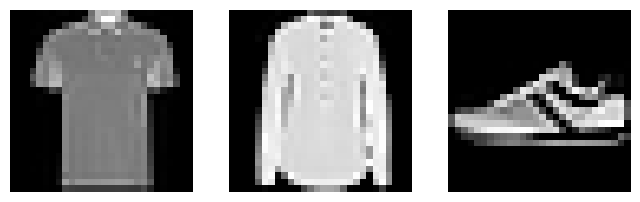

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(8, 4))
for i in range(3):
  ax[i].imshow(X[i][0], cmap='gray')
  ax[i].axis('off')
plt.show()


In [ ]:
norm_2d = nn.BatchNorm2d(1)
output = norm_2d(X)

In [ ]:
output.shape

torch.Size([3, 1, 28, 28])

In [ ]:
arr = torch.randn(3,2)
torch.mean(arr, dim=(0, 1))

tensor(0.4467)

In [ ]:
arr

tensor([[-0.2619,  1.9113],
        [ 1.0482, -1.1489],
        [ 1.7327, -0.6011]])

In [ ]:
torch.mean(output), torch.var(output)


(tensor(-1.3178e-09, grad_fn=<MeanBackward0>),
 tensor(1.0003, grad_fn=<VarBackward0>))

In [ ]:
transform = transforms.ToTensor()

train_dataset_or = torchvision.datasets.USPS(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.USPS(
    root="./data",
    train=False,
    download=True,
    transform=transform
)
train_dataset, valid_dataset = random_split(train_dataset_or, [0.9, 0.1])
train_loader = DataLoader(train_dataset, shuffle=True, batch_size=64)
test_loader = DataLoader(test_dataset, shuffle=False, batch_size=64)
valid_loader = DataLoader(valid_dataset, shuffle=False, batch_size=64)
len(valid_loader), len(train_loader)*64, len(test_loader), len(train_dataset)



(12, 6592, 32, 6562)

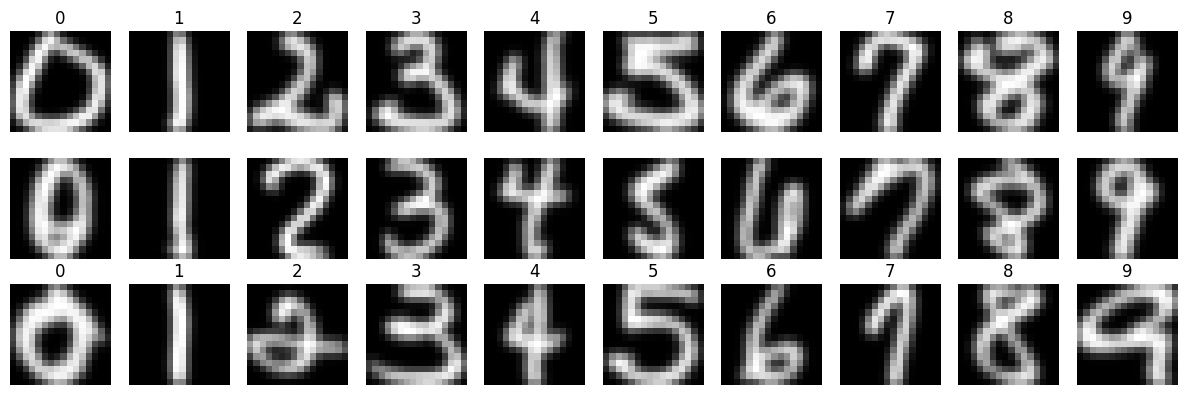

In [ ]:
X, y = train_dataset_or.data, np.array(train_dataset_or.targets)
fig, ax = plt.subplots(3, 10, figsize=(12,4))
for r in range(3):
  for c in range(10):
    idx = np.where(y==c)[0][r]
    ax[r, c].imshow(X[idx], cmap='gray')
    ax[r, c].axis('off')
    if r != 1:
      ax[r, c].set_title(f'{y[idx]}')
plt.tight_layout()
plt.show()

In [ ]:
class Digit_Classifier(nn.Module):
  def __init__(self, n_hidden_1, n_hidden_2, norm='1d'):
    super().__init__()
    if norm == '1d':
      self.model = nn.Sequential(
          nn.Flatten(),
          nn.Linear(16*16, n_hidden_1, bias=False),
          nn.BatchNorm1d(n_hidden_1, momentum=0.2),
          nn.LeakyReLU(0.09),
          nn.Linear(n_hidden_1, n_hidden_2, bias=False),
          nn.BatchNorm1d(n_hidden_2, momentum=0.2),
          nn.LeakyReLU(0.09),
          nn.Linear(n_hidden_2, 10, bias=True)
      )
    elif norm == '2d':
      self.model = nn.Sequential(
          nn.BatchNorm2d(1, momentum=0.01),
          nn.Flatten(),
          nn.Linear(16*16, n_hidden_1, bias=False),
          nn.BatchNorm1d(n_hidden_1, momentum=0.2),
          nn.LeakyReLU(0.09),
          nn.Linear(n_hidden_1, n_hidden_2, bias=False),
          nn.BatchNorm1d(n_hidden_2, momentum=0.2),
          nn.LeakyReLU(0.09),
          nn.Linear(n_hidden_2, 10, bias=True)
      )
  def forward(self, X:torch.tensor):
    return self.model(X)

In [ ]:
def init(m):
  if isinstance(m, nn.Linear):
    nn.init.kaiming_normal_(m.weight, mode='fan_in', a=0.09, nonlinearity='leaky_relu')
    if m.bias is not None:
      nn.init.zeros_(m.bias)

model = Digit_Classifier(64, 32, norm='1d').to(device)
model.apply(init)

model_2d = Digit_Classifier(64, 32, norm='2d').to(device)
model_2d.apply(init)

Digit_Classifier(
  (model): Sequential(
    (0): BatchNorm2d(1, eps=1e-05, momentum=0.01, affine=True, bias=True, track_running_stats=True)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=256, out_features=64, bias=False)
    (3): BatchNorm1d(64, eps=1e-05, momentum=0.2, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.09)
    (5): Linear(in_features=64, out_features=32, bias=False)
    (6): BatchNorm1d(32, eps=1e-05, momentum=0.2, affine=True, bias=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.09)
    (8): Linear(in_features=32, out_features=10, bias=True)
  )
)

In [ ]:
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(weight_decay=1e-3, params=model.parameters(), lr=1e-3)
optimizer_2 = torch.optim.Adam(weight_decay=1e-3, params=model_2d.parameters(), lr=1e-3)

def train_and_validate(
    model, train_loader, valid_loader,
    loss_function, optimizer, epochs
):
  train_history, valid_history = [], []
  for epoch in range(epochs):
    model.train()
    train_loss, valid_loss = 0, 0
    for X_train, y_train in train_loader:
      X_train = X_train.to(device)
      y_train = y_train.to(device)
      loss = loss_function(model(X_train), y_train)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      train_loss += loss.item()

    model.eval()
    with torch.inference_mode():
      for X_valid, y_valid in valid_loader:
        X_valid = X_valid.to(device)
        y_valid = y_valid.to(device)
        loss = loss_function(model(X_valid), y_valid)
        valid_loss += loss.item()
    train_history.append(train_loss/len(train_loader))
    valid_history.append(valid_loss/len(valid_loader))
  return train_history, valid_history


In [ ]:
t, v = train_and_validate(model, train_loader, valid_loader, loss_function, optimizer, 25)
t2, v2 = train_and_validate(model_2d, train_loader, valid_loader, loss_function, optimizer_2, 25)

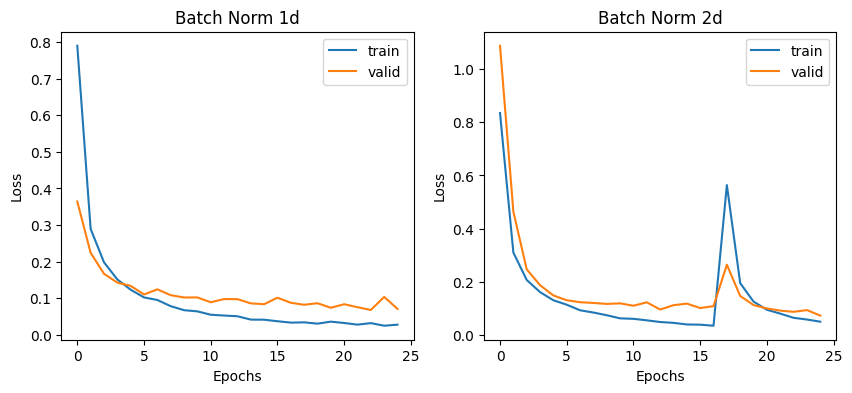

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].plot(t, label='train')
ax[0].plot(v, label='valid')
ax[1].plot(t2, label='train')
ax[1].plot(v2, label='valid')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Loss')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Loss')
ax[0].set_title('Batch Norm 1d')
ax[1].set_title('Batch Norm 2d')
ax[0].legend()
ax[1].legend()
plt.show()

In [ ]:
def evaluate(model, test_loader):
  model.eval()
  metric = PrecisionRecallCurve(task='multiclass', num_classes=10).to(device)
  metric_2 = MulticlassAccuracy(num_classes=10).to(device)
  with torch.inference_mode():
    for X_test, y_test in test_loader:
      X_test = X_test.to(device)
      y_test = y_test.to(device)
      y_pred = model(X_test)
      metric.update(y_pred, y_test)
      metric_2.update(y_pred, y_test)
  metric.plot()
  return metric_2.compute()

tensor(0.9357, device='cuda:0')

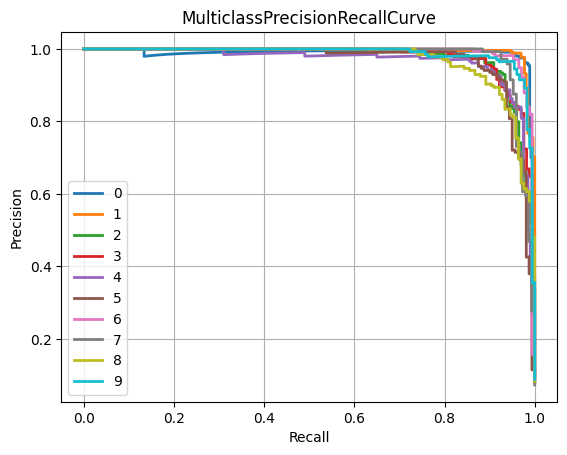

In [ ]:
evaluate(model_2d, test_loader)

tensor(0.9336, device='cuda:0')

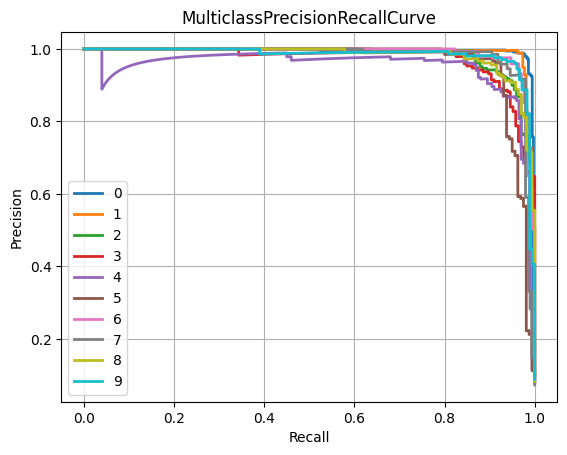

In [ ]:
evaluate(model, test_loader)

In [ ]:
def cm(model, test_loader):
  model.eval()
  metric = ConfusionMatrix(task='multiclass', num_classes=10, normalize='true').to(device)
  with torch.inference_mode():
    for X_test, y_test in test_loader:
      X_test = X_test.to(device)
      y_test = y_test.to(device)
      y_pred = model(X_test)
      metric.update(y_pred, y_test)
  plt.figure(figsize=(8, 6))
  metric.plot(labels=list(range(10)), cmap='Blues', ax=plt.gca())
  plt.title('Confusion Matrix')
  plt.show()


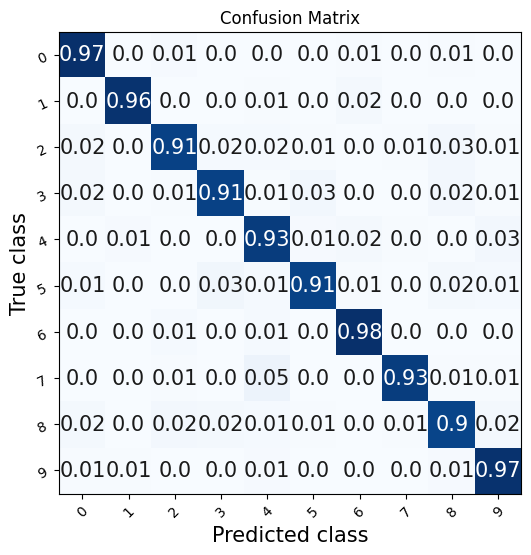

In [ ]:
cm(model_2d, test_loader)

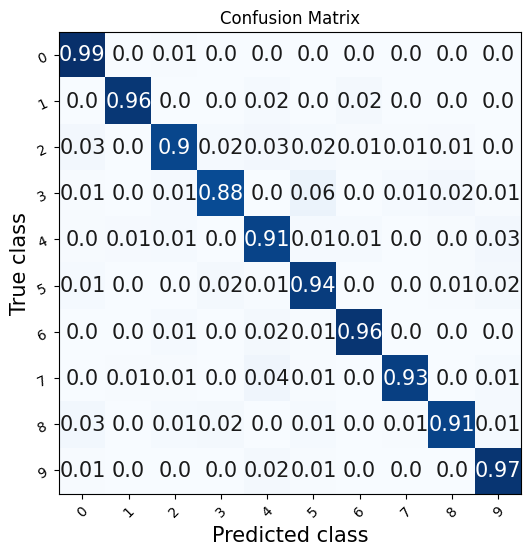

In [ ]:
cm(model, test_loader)